In [4]:
import pandas as pd

print("Pandas imported successfully!")

Pandas imported successfully!


In [5]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 2.3.3


In [7]:
columns = [
    "Class",
    "Age",
    "Menopause",
    "Tumor-Size",
    "Inv-Nodes",
    "Node-Caps",
    "Deg-Malig",
    "Breast",
    "Breast-Quad",
    "Irradiat"
]

df = pd.read_csv(
    "../01_Raw_Data/breast-cancer.data",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 287
Columns: 10


In [8]:
print("Last 10 rows of the dataset:")
display(df.tail(10))

Last 10 rows of the dataset:


,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat
277,recurrence-events,30-39,premeno,25-29,6-8,yes,3,left,right_low,yes
278,recurrence-events,60-69,ge40,10-14,6-8,yes,3,left,left_up,yes
279,recurrence-events,50-59,premeno,35-39,15-17,yes,3,right,right_up,no
280,recurrence-events,50-59,ge40,40-44,6-8,yes,3,left,left_low,yes
281,recurrence-events,50-59,ge40,40-44,6-8,yes,3,left,left_low,yes
282,recurrence-events,30-39,premeno,30-34,0-2,no,2,left,left_up,no
283,recurrence-events,30-39,premeno,20-24,0-2,no,3,left,left_up,yes
284,recurrence-events,60-69,ge40,20-24,0-2,no,1,right,left_up,no
285,recurrence-events,40-49,ge40,30-34,3-5,no,3,left,left_low,no
286,recurrence-events,50-59,ge40,30-34,3-5,no,3,left,left_low,no


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (287, 10)

Column Names:
['Class', 'Age', 'Menopause', 'Tumor-Size', 'Inv-Nodes', 'Node-Caps', 'Deg-Malig', 'Breast', 'Breast-Quad', 'Irradiat']

Data Types:
Class          object
Age            object
Menopause      object
Tumor-Size     object
Inv-Nodes      object
Node-Caps      object
Deg-Malig      object
Breast         object
Breast-Quad    object
Irradiat       object
dtype: object


In [10]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Class          0
Age            0
Menopause      0
Tumor-Size     0
Inv-Nodes      0
Node-Caps      0
Deg-Malig      0
Breast         0
Breast-Quad    0
Irradiat       0
dtype: int64


In [11]:
print("Missing value markers (?) in each column:")
print((df == "?").sum())

Missing value markers (?) in each column:
Class          0
Age            0
Menopause      0
Tumor-Size     0
Inv-Nodes      0
Node-Caps      8
Deg-Malig      0
Breast         0
Breast-Quad    1
Irradiat       0
dtype: int64


In [12]:
print("Class distribution:")
print(df["Class"].value_counts())

Class distribution:
Class
no-recurrence-events    201
recurrence-events        85
Class                     1
Name: count, dtype: int64


In [13]:
print("Rows containing 'Class':")
display(df[df["Class"] == "Class"])

Rows containing 'Class':


,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat
0,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat


In [14]:
df = df[df["Class"] != "Class"].reset_index(drop=True)

print("Rows after removing the header row:", df.shape[0])
print("Columns:", df.shape[1])

Rows after removing the header row: 286
Columns: 10


In [15]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 14


In [16]:
print("Duplicate rows:")
display(df[df.duplicated(keep=False)])

Duplicate rows:


,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
5,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,left,left_low,no
6,no-recurrence-events,50-59,premeno,25-29,0-2,no,2,left,left_low,no
7,no-recurrence-events,60-69,ge40,20-24,0-2,no,1,left,left_low,no
9,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,left_up,no
21,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,left,left_low,no
37,no-recurrence-events,50-59,ge40,15-19,0-2,no,1,right,central,no
65,no-recurrence-events,40-49,premeno,10-14,0-2,no,1,right,left_up,no
67,no-recurrence-events,50-59,ge40,20-24,0-2,no,3,left,left_up,no
78,no-recurrence-events,50-59,premeno,25-29,0-2,no,2,left,left_low,no


In [17]:
duplicate_groups = (
    df[df.duplicated(keep=False)]
    .value_counts()
    .reset_index(name="Count")
)

print("Duplicate groups:")
display(duplicate_groups)

Duplicate groups:


,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat,Count
0,no-recurrence-events,30-39,premeno,15-19,0-2,no,1,left,left_low,no,2
1,no-recurrence-events,40-49,premeno,10-14,0-2,no,1,right,left_up,no,2
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,left_up,no,2
3,no-recurrence-events,50-59,ge40,15-19,0-2,no,1,right,central,no,2
4,no-recurrence-events,50-59,ge40,20-24,0-2,no,3,left,left_up,no,2
5,no-recurrence-events,50-59,premeno,25-29,0-2,no,2,left,left_low,no,2
6,no-recurrence-events,60-69,ge40,10-14,0-2,no,1,left,left_up,no,2
7,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,left,left_low,no,2
8,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no,2
9,no-recurrence-events,60-69,ge40,20-24,0-2,no,1,left,left_low,no,2


In [18]:
print("Rows containing missing-value markers:")
display(df[(df == "?").any(axis=1)])

Rows containing missing-value markers:


,Class,Age,Menopause,Tumor-Size,Inv-Nodes,Node-Caps,Deg-Malig,Breast,Breast-Quad,Irradiat
145,no-recurrence-events,40-49,premeno,25-29,0-2,?,2,left,right_low,yes
163,no-recurrence-events,60-69,ge40,25-29,3-5,?,1,right,left_up,yes
164,no-recurrence-events,60-69,ge40,25-29,3-5,?,1,right,left_low,yes
183,no-recurrence-events,50-59,ge40,30-34,9-11,?,3,left,left_up,yes
184,no-recurrence-events,50-59,ge40,30-34,9-11,?,3,left,left_low,yes
206,recurrence-events,50-59,ge40,30-34,0-2,no,3,left,?,no
233,recurrence-events,70-79,ge40,15-19,9-11,?,1,left,left_low,yes
263,recurrence-events,50-59,lt40,20-24,0-2,?,1,left,left_up,no
264,recurrence-events,50-59,lt40,20-24,0-2,?,1,left,left_low,no


In [19]:
print("Node-Caps distribution:")
print(df["Node-Caps"].value_counts())

Node-Caps distribution:
Node-Caps
no     222
yes     56
?        8
Name: count, dtype: int64


In [20]:
print("Breast-Quad distribution:")
print(df["Breast-Quad"].value_counts())

Breast-Quad distribution:
Breast-Quad
left_low     110
left_up       97
right_up      33
right_low     24
central       21
?              1
Name: count, dtype: int64


In [21]:
# Replace missing-value markers with the mode of each column

node_caps_mode = df["Node-Caps"].replace("?", pd.NA).mode()[0]
breast_quad_mode = df["Breast-Quad"].replace("?", pd.NA).mode()[0]

df["Node-Caps"] = df["Node-Caps"].replace("?", node_caps_mode)
df["Breast-Quad"] = df["Breast-Quad"].replace("?", breast_quad_mode)

print("Node-Caps missing values replaced with:", node_caps_mode)
print("Breast-Quad missing values replaced with:", breast_quad_mode)

Node-Caps missing values replaced with: no
Breast-Quad missing values replaced with: left_low


In [22]:
print("Missing-value markers after cleaning:")
print((df == "?").sum())

Missing-value markers after cleaning:
Class          0
Age            0
Menopause      0
Tumor-Size     0
Inv-Nodes      0
Node-Caps      0
Deg-Malig      0
Breast         0
Breast-Quad    0
Irradiat       0
dtype: int64


In [23]:
print("Dataset shape after cleaning:")
print(df.shape)

Dataset shape after cleaning:
(286, 10)


In [24]:
print("Missing-value markers after cleaning:")
print((df == "?").sum())

print("\nDataset shape after cleaning:")
print(df.shape)

Missing-value markers after cleaning:
Class          0
Age            0
Menopause      0
Tumor-Size     0
Inv-Nodes      0
Node-Caps      0
Deg-Malig      0
Breast         0
Breast-Quad    0
Irradiat       0
dtype: int64

Dataset shape after cleaning:
(286, 10)


In [25]:
print("Data Types:")
print(df.dtypes)

print("\nUnique Values in Each Column:")
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].unique())

Data Types:
Class          object
Age            object
Menopause      object
Tumor-Size     object
Inv-Nodes      object
Node-Caps      object
Deg-Malig      object
Breast         object
Breast-Quad    object
Irradiat       object
dtype: object

Unique Values in Each Column:

Class:
['no-recurrence-events' 'recurrence-events']

Age:
['30-39' '40-49' '60-69' '50-59' '70-79' '20-29']

Menopause:
['premeno' 'ge40' 'lt40']

Tumor-Size:
['30-34' '20-24' '15-19' '0-4' '25-29' '50-54' '10-14' '40-44' '35-39'
 '5-9' '45-49']

Inv-Nodes:
['0-2' '6-8' '9-11' '3-5' '15-17' '12-14' '24-26']

Node-Caps:
['no' 'yes']

Deg-Malig:
['3' '2' '1']

Breast:
['left' 'right']

Breast-Quad:
['left_low' 'right_up' 'left_up' 'right_low' 'central']

Irradiat:
['no' 'yes']


In [26]:
print("Number of unique values in each column:\n")

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

Number of unique values in each column:

Class: 2 unique values
Age: 6 unique values
Menopause: 3 unique values
Tumor-Size: 11 unique values
Inv-Nodes: 7 unique values
Node-Caps: 2 unique values
Deg-Malig: 3 unique values
Breast: 2 unique values
Breast-Quad: 5 unique values
Irradiat: 2 unique values


In [27]:
print("Value counts for each feature:\n")

for column in df.columns:
    print(f"\n{'='*40}")
    print(column)
    print(f"{'='*40}")
    print(df[column].value_counts())

Value counts for each feature:


Class
Class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64

Age
Age
50-59    96
40-49    90
60-69    57
30-39    36
70-79     6
20-29     1
Name: count, dtype: int64

Menopause
Menopause
premeno    150
ge40       129
lt40         7
Name: count, dtype: int64

Tumor-Size
Tumor-Size
30-34    60
25-29    54
20-24    50
15-19    30
10-14    28
40-44    22
35-39    19
50-54     8
0-4       8
5-9       4
45-49     3
Name: count, dtype: int64

Inv-Nodes
Inv-Nodes
0-2      213
3-5       36
6-8       17
9-11      10
15-17      6
12-14      3
24-26      1
Name: count, dtype: int64

Node-Caps
Node-Caps
no     230
yes     56
Name: count, dtype: int64

Deg-Malig
Deg-Malig
2    130
3     85
1     71
Name: count, dtype: int64

Breast
Breast
left     152
right    134
Name: count, dtype: int64

Breast-Quad
Breast-Quad
left_low     111
left_up       97
right_up      33
right_low     24
central       21
Name: count, dtype: int64

Irradiat

In [28]:
# Create a complete frequency table for all features

frequency_table = []

for column in df.columns:
    counts = df[column].value_counts()

    for value, count in counts.items():
        frequency_table.append({
            "Feature": column,
            "Value": value,
            "Count": count
        })

frequency_df = pd.DataFrame(frequency_table)

print(frequency_df.to_string(index=False))

    Feature                Value  Count
      Class no-recurrence-events    201
      Class    recurrence-events     85
        Age                50-59     96
        Age                40-49     90
        Age                60-69     57
        Age                30-39     36
        Age                70-79      6
        Age                20-29      1
  Menopause              premeno    150
  Menopause                 ge40    129
  Menopause                 lt40      7
 Tumor-Size                30-34     60
 Tumor-Size                25-29     54
 Tumor-Size                20-24     50
 Tumor-Size                15-19     30
 Tumor-Size                10-14     28
 Tumor-Size                40-44     22
 Tumor-Size                35-39     19
 Tumor-Size                50-54      8
 Tumor-Size                  0-4      8
 Tumor-Size                  5-9      4
 Tumor-Size                45-49      3
  Inv-Nodes                  0-2    213
  Inv-Nodes                  3-5     36


In [29]:
# Create a copy of the cleaned dataset for further preprocessing

df_cleaned = df.copy()

print("Cleaned dataset copy created.")
print("Shape:", df_cleaned.shape)

Cleaned dataset copy created.
Shape: (286, 10)


In [30]:
# Encode binary categorical features

df_cleaned["Node-Caps"] = df_cleaned["Node-Caps"].map({
    "no": 0,
    "yes": 1
})

df_cleaned["Breast"] = df_cleaned["Breast"].map({
    "left": 0,
    "right": 1
})

df_cleaned["Irradiat"] = df_cleaned["Irradiat"].map({
    "no": 0,
    "yes": 1
})

# Encode the target variable
df_cleaned["Class"] = df_cleaned["Class"].map({
    "no-recurrence-events": 0,
    "recurrence-events": 1
})

print("Binary encoding completed.")
print(df_cleaned[["Class", "Node-Caps", "Breast", "Irradiat"]].head())

Binary encoding completed.
   Class  Node-Caps  Breast  Irradiat
0      0          0       0         0
1      0          0       1         0
2      0          0       0         0
3      0          0       1         0
4      0          0       1         0


In [31]:
# Convert range-based features to their midpoint values

def range_to_midpoint(value):
    start, end = value.split("-")
    return (int(start) + int(end)) / 2


df_cleaned["Age"] = df_cleaned["Age"].apply(range_to_midpoint)
df_cleaned["Tumor-Size"] = df_cleaned["Tumor-Size"].apply(range_to_midpoint)
df_cleaned["Inv-Nodes"] = df_cleaned["Inv-Nodes"].apply(range_to_midpoint)

print("Range-based features converted to midpoint values.")

print("\nConverted features:")
print(df_cleaned[["Age", "Tumor-Size", "Inv-Nodes"]].head())

Range-based features converted to midpoint values.

Converted features:
    Age  Tumor-Size  Inv-Nodes
0  34.5        32.0        1.0
1  44.5        22.0        1.0
2  44.5        22.0        1.0
3  64.5        17.0        1.0
4  44.5         2.0        1.0


In [32]:
# Convert degree of malignancy to numeric

df_cleaned["Deg-Malig"] = pd.to_numeric(df_cleaned["Deg-Malig"])

print("Deg-Malig converted to numeric.")
print(df_cleaned["Deg-Malig"].value_counts().sort_index())
print("\nData type:", df_cleaned["Deg-Malig"].dtype)

Deg-Malig converted to numeric.
Deg-Malig
1     71
2    130
3     85
Name: count, dtype: int64

Data type: int64


In [33]:
# One-hot encode nominal categorical features

df_cleaned = pd.get_dummies(
    df_cleaned,
    columns=["Menopause", "Breast-Quad"],
    dtype=int
)

print("One-hot encoding completed.")

print("\nNew dataset columns:")
print(df_cleaned.columns.tolist())

print("\nDataset shape:")
print(df_cleaned.shape)

One-hot encoding completed.

New dataset columns:
['Class', 'Age', 'Tumor-Size', 'Inv-Nodes', 'Node-Caps', 'Deg-Malig', 'Breast', 'Irradiat', 'Menopause_ge40', 'Menopause_lt40', 'Menopause_premeno', 'Breast-Quad_central', 'Breast-Quad_left_low', 'Breast-Quad_left_up', 'Breast-Quad_right_low', 'Breast-Quad_right_up']

Dataset shape:
(286, 16)


In [34]:
# Check for missing values after all transformations

print("Missing values after transformation:")
print(df_cleaned.isnull().sum())

print("\nData types after transformation:")
print(df_cleaned.dtypes)

print("\nFinal transformed dataset shape:")
print(df_cleaned.shape)

Missing values after transformation:
Class                    0
Age                      0
Tumor-Size               0
Inv-Nodes                0
Node-Caps                0
Deg-Malig                0
Breast                   0
Irradiat                 0
Menopause_ge40           0
Menopause_lt40           0
Menopause_premeno        0
Breast-Quad_central      0
Breast-Quad_left_low     0
Breast-Quad_left_up      0
Breast-Quad_right_low    0
Breast-Quad_right_up     0
dtype: int64

Data types after transformation:
Class                      int64
Age                      float64
Tumor-Size               float64
Inv-Nodes                float64
Node-Caps                  int64
Deg-Malig                  int64
Breast                     int64
Irradiat                   int64
Menopause_ge40             int64
Menopause_lt40             int64
Menopause_premeno          int64
Breast-Quad_central        int64
Breast-Quad_left_low       int64
Breast-Quad_left_up        int64
Breast-Quad_right_low 

In [35]:
# Create a separate dataset for Machine Learning

df_ml = df_cleaned.copy()

print("ML dataset created.")
print("Shape:", df_ml.shape)

ML dataset created.
Shape: (286, 16)


In [36]:
# Save the cleaned and transformed dataset

output_path = "../02_Cleaned_Data/breast_cancer_cleaned.csv"

df_cleaned.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print("File:", output_path)
print("Shape:", df_cleaned.shape)

Cleaned dataset saved successfully.
File: ../02_Cleaned_Data/breast_cancer_cleaned.csv
Shape: (286, 16)


In [37]:
# Final validation of the cleaned and transformed dataset

print("===== FINAL DATASET VALIDATION =====")

print("\nDataset shape:")
print(df_cleaned.shape)

print("\nMissing values:")
print(df_cleaned.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_cleaned.duplicated().sum())

print("\nData types:")
print(df_cleaned.dtypes)

print("\nFirst 5 rows:")
print(df_cleaned.head())

===== FINAL DATASET VALIDATION =====

Dataset shape:
(286, 16)

Missing values:
0

Duplicate rows:
14

Data types:
Class                      int64
Age                      float64
Tumor-Size               float64
Inv-Nodes                float64
Node-Caps                  int64
Deg-Malig                  int64
Breast                     int64
Irradiat                   int64
Menopause_ge40             int64
Menopause_lt40             int64
Menopause_premeno          int64
Breast-Quad_central        int64
Breast-Quad_left_low       int64
Breast-Quad_left_up        int64
Breast-Quad_right_low      int64
Breast-Quad_right_up       int64
dtype: object

First 5 rows:
   Class   Age  Tumor-Size  Inv-Nodes  Node-Caps  Deg-Malig  Breast  Irradiat  \
0      0  34.5        32.0        1.0          0          3       0         0   
1      0  44.5        22.0        1.0          0          2       1         0   
2      0  44.5        22.0        1.0          0          2       0         0   
3   

In [2]:
import pandas as pd

# Load the cleaned dataset
cleaned_path = "../02_Cleaned_Data/breast_cancer_cleaned.csv"

df_cleaned = pd.read_csv(cleaned_path)

print("Cleaned dataset loaded successfully!")
print("Shape:", df_cleaned.shape)

Cleaned dataset loaded successfully!
Shape: (286, 16)


In [3]:
print("===== DUPLICATE ANALYSIS =====")

# Count duplicate rows
duplicate_count = df_cleaned.duplicated().sum()
print("\nTotal duplicate rows:", duplicate_count)

# Display all duplicate rows
duplicates = df_cleaned[df_cleaned.duplicated(keep=False)]

print("\nDuplicate rows:")
print(duplicates)

# Count how many times each duplicate record appears
print("\nDuplicate group counts:")
print(duplicates.value_counts())

===== DUPLICATE ANALYSIS =====

Total duplicate rows: 14

Duplicate rows:
     Class   Age  Tumor-Size  Inv-Nodes  Node-Caps  Deg-Malig  Breast  \
3        0  64.5        17.0        1.0          0          2       1   
5        0  64.5        17.0        1.0          0          2       0   
6        0  54.5        27.0        1.0          0          2       0   
7        0  64.5        22.0        1.0          0          1       0   
9        0  44.5        22.0        1.0          0          2       1   
21       0  64.5        17.0        1.0          0          2       0   
37       0  54.5        17.0        1.0          0          1       1   
65       0  44.5        12.0        1.0          0          1       1   
67       0  54.5        22.0        1.0          0          3       0   
78       0  54.5        27.0        1.0          0          2       0   
81       0  64.5        12.0        1.0          0          1       0   
91       0  54.5        22.0        1.0          0

In [4]:
print("===== REMOVING DUPLICATES =====")

# Number of rows before removal
before = len(df_cleaned)

# Remove exact duplicate rows
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)

# Number of rows after removal
after = len(df_cleaned)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicate rows removed:", before - after)

===== REMOVING DUPLICATES =====
Rows before removing duplicates: 286
Rows after removing duplicates: 272
Duplicate rows removed: 14


In [5]:
print("===== FINAL CLEANING VALIDATION =====")

print("\nDataset shape:")
print(df_cleaned.shape)

print("\nMissing values:")
print(df_cleaned.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_cleaned.duplicated().sum())

print("\nData types:")
print(df_cleaned.dtypes)

print("\nFirst 5 rows:")
print(df_cleaned.head())

===== FINAL CLEANING VALIDATION =====

Dataset shape:
(272, 16)

Missing values:
0

Duplicate rows:
0

Data types:
Class                      int64
Age                      float64
Tumor-Size               float64
Inv-Nodes                float64
Node-Caps                  int64
Deg-Malig                  int64
Breast                     int64
Irradiat                   int64
Menopause_ge40             int64
Menopause_lt40             int64
Menopause_premeno          int64
Breast-Quad_central        int64
Breast-Quad_left_low       int64
Breast-Quad_left_up        int64
Breast-Quad_right_low      int64
Breast-Quad_right_up       int64
dtype: object

First 5 rows:
   Class   Age  Tumor-Size  Inv-Nodes  Node-Caps  Deg-Malig  Breast  Irradiat  \
0      0  34.5        32.0        1.0          0          3       0         0   
1      0  44.5        22.0        1.0          0          2       1         0   
2      0  44.5        22.0        1.0          0          2       0         0   
3   

In [6]:
print("===== FEATURE ASSESSMENT =====")

# Target variable
target = "Class"

# Separate target and input features
X = df_cleaned.drop(columns=[target])
y = df_cleaned[target]

print("\nTarget variable:")
print(target)

print("\nNumber of features:")
print(X.shape[1])

print("\nFeature names:")
print(list(X.columns))

print("\nTarget distribution:")
print(y.value_counts())

===== FEATURE ASSESSMENT =====

Target variable:
Class

Number of features:
15

Feature names:
['Age', 'Tumor-Size', 'Inv-Nodes', 'Node-Caps', 'Deg-Malig', 'Breast', 'Irradiat', 'Menopause_ge40', 'Menopause_lt40', 'Menopause_premeno', 'Breast-Quad_central', 'Breast-Quad_left_low', 'Breast-Quad_left_up', 'Breast-Quad_right_low', 'Breast-Quad_right_up']

Target distribution:
Class
0    191
1     81
Name: count, dtype: int64


In [7]:
print("===== FEATURE-TARGET CORRELATION =====")

# Calculate correlation of every feature with the target
correlation = df_cleaned.corr(numeric_only=True)["Class"].drop("Class")

# Sort by absolute correlation
correlation_sorted = correlation.abs().sort_values(ascending=False)

print("\nFeatures ranked by absolute correlation with Class:")

for feature in correlation_sorted.index:
    print(f"{feature}: {correlation[feature]:.4f}")

===== FEATURE-TARGET CORRELATION =====

Features ranked by absolute correlation with Class:
Deg-Malig: 0.2869
Inv-Nodes: 0.2747
Node-Caps: 0.2727
Irradiat: 0.1875
Tumor-Size: 0.1504
Breast-Quad_right_up: 0.0616
Breast-Quad_central: -0.0602
Age: -0.0582
Breast: -0.0550
Menopause_premeno: 0.0389
Menopause_ge40: -0.0377
Breast-Quad_left_low: 0.0336
Breast-Quad_right_low: -0.0325
Breast-Quad_left_up: -0.0237
Menopause_lt40: -0.0043


In [9]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

print("===== RANDOM FOREST FEATURE IMPORTANCE =====")

# Create Random Forest model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train using all features
rf.fit(X, y)

# Get feature importance
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeatures ranked by Random Forest importance:")

for feature, importance in feature_importance.items():
    print(f"{feature}: {importance:.4f}")

===== RANDOM FOREST FEATURE IMPORTANCE =====

Features ranked by Random Forest importance:
Tumor-Size: 0.2488
Deg-Malig: 0.1301
Age: 0.1278
Inv-Nodes: 0.1099
Breast: 0.0592
Node-Caps: 0.0592
Irradiat: 0.0549
Breast-Quad_left_up: 0.0365
Breast-Quad_left_low: 0.0364
Menopause_premeno: 0.0317
Menopause_ge40: 0.0307
Breast-Quad_right_up: 0.0279
Breast-Quad_central: 0.0191
Breast-Quad_right_low: 0.0179
Menopause_lt40: 0.0100


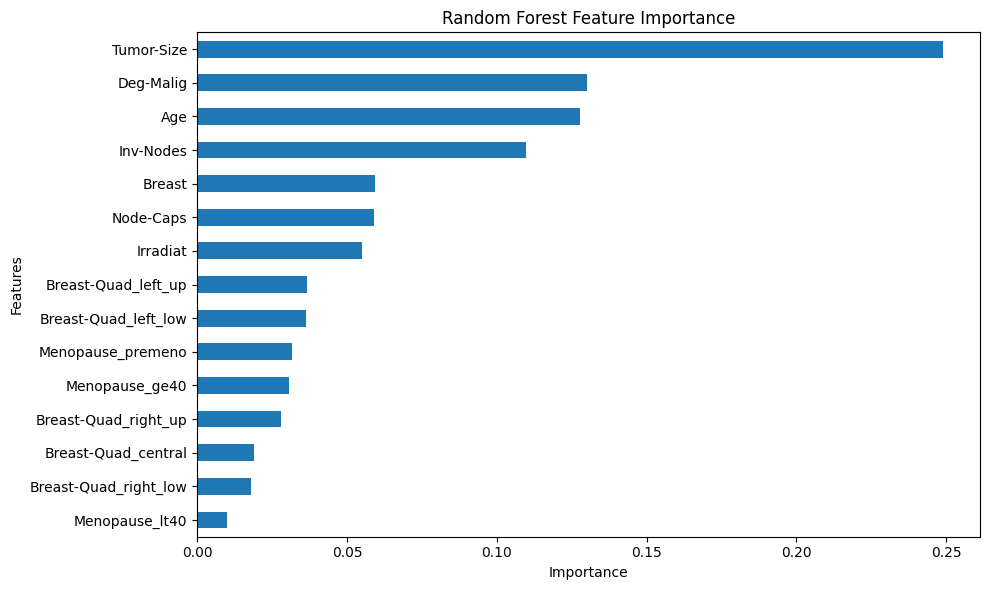

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.show()

In [6]:
import pandas as pd

print("===== RESTORING CLEANED DATASET =====")

# Load the saved cleaned dataset
cleaned_path = "../02_Cleaned_Data/breast_cancer_cleaned.csv"

df_cleaned = pd.read_csv(cleaned_path)

print("Dataset loaded:", df_cleaned.shape)

# Remove the 14 exact duplicate records
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)

print("After duplicate removal:", df_cleaned.shape)
print("Missing values:", df_cleaned.isnull().sum().sum())
print("Duplicate rows:", df_cleaned.duplicated().sum())

===== RESTORING CLEANED DATASET =====
Dataset loaded: (286, 16)
After duplicate removal: (272, 16)
Missing values: 0
Duplicate rows: 0


In [3]:
print("===== ML DATA PREPARATION =====")

# Input features
X = df_cleaned.drop(columns=["Class"])

# Target variable
y = df_cleaned["Class"]

print("\nFeature matrix (X):")
print("Shape:", X.shape)

print("\nTarget variable (y):")
print("Shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(list(X.columns))

===== ML DATA PREPARATION =====

Feature matrix (X):
Shape: (272, 15)

Target variable (y):
Shape: (272,)

Target distribution:
Class
0    191
1     81
Name: count, dtype: int64

Feature columns:
['Age', 'Tumor-Size', 'Inv-Nodes', 'Node-Caps', 'Deg-Malig', 'Breast', 'Irradiat', 'Menopause_ge40', 'Menopause_lt40', 'Menopause_premeno', 'Breast-Quad_central', 'Breast-Quad_left_low', 'Breast-Quad_left_up', 'Breast-Quad_right_low', 'Breast-Quad_right_up']


In [4]:
from sklearn.model_selection import train_test_split

print("===== TRAIN-TEST SPLIT =====")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTesting set:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

===== TRAIN-TEST SPLIT =====

Training set:
X_train shape: (217, 15)
y_train shape: (217,)

Testing set:
X_test shape: (55, 15)
y_test shape: (55,)

Training class distribution:
Class
0    152
1     65
Name: count, dtype: int64

Testing class distribution:
Class
0    39
1    16
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import StandardScaler

print("===== FEATURE SCALING =====")

# Create the scaler
scaler = StandardScaler()

# Fit only on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("\nOriginal training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nScaling completed successfully.")

===== FEATURE SCALING =====

Original training shape: (217, 15)
Scaled training shape: (217, 15)

Original testing shape: (55, 15)
Scaled testing shape: (55, 15)

Scaling completed successfully.


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("===== ML MODEL PREPARATION =====")

# Define classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    )
}

print("\nModels prepared:")
for name in models:
    print("-", name)

print("\nTotal models:", len(models))

===== ML MODEL PREPARATION =====

Models prepared:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM

Total models: 5


In [7]:
from sklearn.metrics import accuracy_score

print("===== MODEL TRAINING =====")

results = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = model.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(f"{name}:")
    print(f"  Accuracy: {accuracy:.4f}")
    print()

print("===== MODEL TRAINING COMPLETED =====")

===== MODEL TRAINING =====
Logistic Regression:
  Accuracy: 0.6545

Decision Tree:
  Accuracy: 0.6364

Random Forest:
  Accuracy: 0.7091

KNN:
  Accuracy: 0.7818

SVM:
  Accuracy: 0.7091

===== MODEL TRAINING COMPLETED =====


In [8]:
from sklearn.metrics import classification_report, confusion_matrix

print("===== DETAILED MODEL EVALUATION =====")

for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test_scaled)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))

===== DETAILED MODEL EVALUATION =====

Logistic Regression

Confusion Matrix:
[[27 12]
 [ 7  9]]

Classification Report:
              precision    recall  f1-score   support

           0     0.7941    0.6923    0.7397        39
           1     0.4286    0.5625    0.4865        16

    accuracy                         0.6545        55
   macro avg     0.6113    0.6274    0.6131        55
weighted avg     0.6878    0.6545    0.6661        55


Decision Tree

Confusion Matrix:
[[26 13]
 [ 7  9]]

Classification Report:
              precision    recall  f1-score   support

           0     0.7879    0.6667    0.7222        39
           1     0.4091    0.5625    0.4737        16

    accuracy                         0.6364        55
   macro avg     0.5985    0.6146    0.5980        55
weighted avg     0.6777    0.6364    0.6499        55


Random Forest

Confusion Matrix:
[[31  8]
 [ 8  8]]

Classification Report:
              precision    recall  f1-score   support

           0    

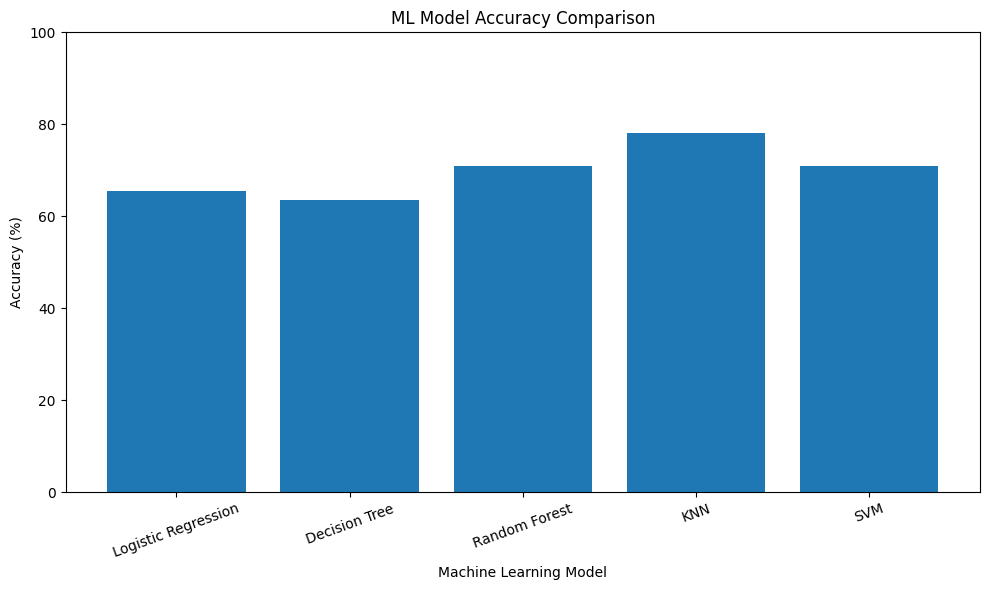

In [9]:
import matplotlib.pyplot as plt

# Convert accuracy results to percentages
model_names = list(results.keys())
accuracies = [results[name] * 100 for name in model_names]

plt.figure(figsize=(10, 6))

plt.bar(model_names, accuracies)

plt.title("ML Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [7]:
# Task 3 – Final Data Preprocessing Verification

print("Final Dataset Shape:", df_cleaned.shape)

print("\nMissing Values:")
print(df_cleaned.isnull().sum())

print("\nTotal Missing Values:", df_cleaned.isnull().sum().sum())

print("\nDuplicate Rows:", df_cleaned.duplicated().sum())

print("\nData Types:")
print(df_cleaned.dtypes)

Final Dataset Shape: (272, 16)

Missing Values:
Class                    0
Age                      0
Tumor-Size               0
Inv-Nodes                0
Node-Caps                0
Deg-Malig                0
Breast                   0
Irradiat                 0
Menopause_ge40           0
Menopause_lt40           0
Menopause_premeno        0
Breast-Quad_central      0
Breast-Quad_left_low     0
Breast-Quad_left_up      0
Breast-Quad_right_low    0
Breast-Quad_right_up     0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0

Data Types:
Class                      int64
Age                      float64
Tumor-Size               float64
Inv-Nodes                float64
Node-Caps                  int64
Deg-Malig                  int64
Breast                     int64
Irradiat                   int64
Menopause_ge40             int64
Menopause_lt40             int64
Menopause_premeno          int64
Breast-Quad_central        int64
Breast-Quad_left_low       int64
Breast-Quad_left_up  

Correlation with Class:
Class                    1.000000
Deg-Malig                0.286857
Inv-Nodes                0.274678
Node-Caps                0.272658
Irradiat                 0.187485
Tumor-Size               0.150377
Breast-Quad_right_up     0.061649
Menopause_premeno        0.038890
Breast-Quad_left_low     0.033574
Menopause_lt40          -0.004293
Breast-Quad_left_up     -0.023741
Breast-Quad_right_low   -0.032514
Menopause_ge40          -0.037679
Breast                  -0.054991
Age                     -0.058178
Breast-Quad_central     -0.060247
Name: Class, dtype: float64


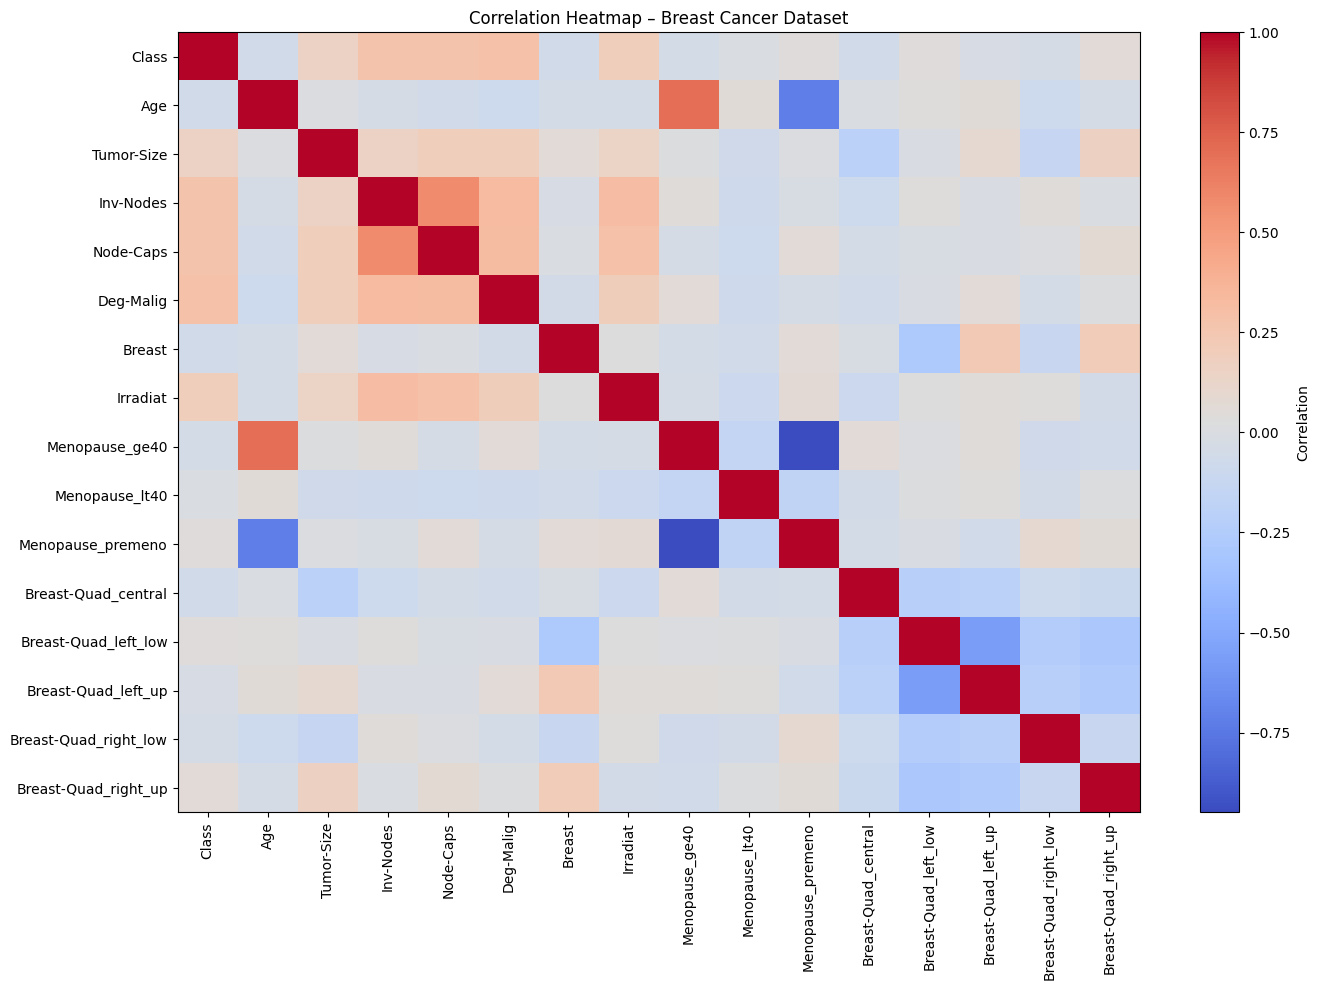

In [9]:
# Task 4 – Correlation Analysis

import matplotlib.pyplot as plt

# Calculate correlation matrix
correlation = df_cleaned.corr(numeric_only=True)

# Correlation with target variable
class_correlation = correlation["Class"].sort_values(ascending=False)

print("Correlation with Class:")
print(class_correlation)

# Correlation heatmap using matplotlib
plt.figure(figsize=(14, 10))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap – Breast Cancer Dataset")
plt.tight_layout()
plt.show()